In [2]:
import sys
print(sys.executable)

C:\Users\Anmol\projectLoka\.venv\Scripts\python.exe


In [3]:
import lightkurve
import pandas as pd
import numpy as np

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
df = pd.read_csv(r"C:\Users\Anmol\projectLoka\new_data.csv", on_bad_lines='skip')
                 


In [5]:
display(df.head(10))


,kepid,kepoi_name,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_period,koi_period_err1,koi_period_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr
0,10797460,K00752.01,CANDIDATE,1.000,0,0,0,9.488036,2.780000e-05,-2.780000e-05,2.95750,0.08190,-0.08190,616.0,19.5,-19.5,93.59,29.45,-16.65,35.8
1,10797460,K00752.02,CANDIDATE,0.969,0,0,0,54.418383,2.480000e-04,-2.480000e-04,4.50700,0.11600,-0.11600,875.0,35.5,-35.5,9.11,2.87,-1.62,25.8
2,10811496,K00753.01,CANDIDATE,0.000,0,0,0,19.899140,1.490000e-05,-1.490000e-05,1.78220,0.03410,-0.03410,10800.0,171.0,-171.0,39.30,31.04,-10.49,76.3
3,10848459,K00754.01,FALSE POSITIVE,0.000,0,1,0,1.736952,2.630000e-07,-2.630000e-07,2.40641,0.00537,-0.00537,8080.0,12.8,-12.8,891.96,668.95,-230.35,505.6
4,10854555,K00755.01,CANDIDATE,1.000,0,0,0,2.525592,3.760000e-06,-3.760000e-06,1.65450,0.04200,-0.04200,603.0,16.9,-16.9,926.16,874.33,-314.24,40.9
5,10872983,K00756.01,CANDIDATE,1.000,0,0,0,11.094321,2.040000e-05,-2.040000e-05,4.59450,0.06100,-0.06100,1520.0,24.2,-24.2,114.81,112.85,-36.70,66.5
6,10872983,K00756.02,CANDIDATE,1.000,0,0,0,4.134435,1.050000e-05,-1.050000e-05,3.14020,0.06730,-0.06730,686.0,18.7,-18.7,427.65,420.33,-136.70,40.2
7,10872983,K00756.03,CANDIDATE,0.992,0,0,0,2.566589,1.780000e-05,-1.780000e-05,2.42900,0.16500,-0.16500,227.0,16.8,-16.8,807.74,793.91,-258.20,15.0
8,6721123,K00114.01,FALSE POSITIVE,0.000,0,1,1,7.361790,2.130000e-05,-2.130000e-05,5.02200,0.13600,-0.13600,234.0,5.8,-5.8,767.22,349.28,-365.49,47.7
9,10910878,K00757.01,CANDIDATE,1.000,0,0,0,16.068647,1.090000e-05,-1.090000e-05,3.53470,0.02410,-0.02410,4910.0,33.3,-33.3,30.75,4.46,-6.66,161.9


In [6]:
print(df.shape)
print(df.info())

(9564, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   koi_pdisposition   9564 non-null   object 
 3   koi_score          8054 non-null   float64
 4   koi_fpflag_nt      9564 non-null   int64  
 5   koi_fpflag_ss      9564 non-null   int64  
 6   koi_fpflag_co      9564 non-null   int64  
 7   koi_period         9564 non-null   float64
 8   koi_period_err1    9110 non-null   float64
 9   koi_period_err2    9110 non-null   float64
 10  koi_duration       9564 non-null   float64
 11  koi_duration_err1  9110 non-null   float64
 12  koi_duration_err2  9110 non-null   float64
 13  koi_depth          9201 non-null   float64
 14  koi_depth_err1     9110 non-null   float64
 15  koi_depth_err2     9110 non-null   float64
 16  koi_insol    

koi_pdisposition
FALSE POSITIVE    4847
CANDIDATE         4717
Name: count, dtype: int64


<Axes: >

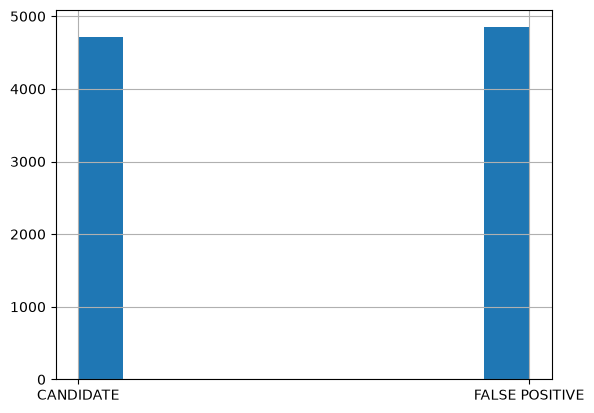

In [7]:
    print(df["koi_pdisposition"].value_counts())
    df["koi_pdisposition"].hist()

In [8]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)


koi_score            1510
koi_period_err1       454
koi_period_err2       454
koi_duration_err1     454
koi_duration_err2     454
koi_depth_err1        454
koi_depth_err2        454
koi_depth             363
koi_model_snr         363
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
dtype: int64


In [9]:
df = df.drop(columns=[
    "kepid",
    "kepoi_name"
], errors="ignore")

In [10]:
    df["target"] = df["koi_pdisposition"].map({
        "CANDIDATE": 1,
        "FALSE POSITIVE": 0
    })

In [11]:
print(df["target"].value_counts())

target
0    4847
1    4717
Name: count, dtype: int64


In [12]:
df = df.drop(columns=["koi_pdisposition"])

In [13]:
print("Dataset shape:", df.shape)

missing = df.isnull().sum()

print("\nMissing values:")
print(missing[missing > 0].sort_values(ascending=False))

Dataset shape: (9564, 18)

Missing values:
koi_score            1510
koi_period_err1       454
koi_period_err2       454
koi_duration_err1     454
koi_duration_err2     454
koi_depth_err1        454
koi_depth_err2        454
koi_depth             363
koi_model_snr         363
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
dtype: int64


In [14]:
df = df.drop(columns=["koi_score"])


In [15]:
missing = df.isnull().sum()
missing = missing[missing > 0]

for column in missing.index:
    print(f"{column:25} → {missing[column]} missing "
          f"({missing[column] / len(df) * 100:.2f}%)")

koi_period_err1           → 454 missing (4.75%)
koi_period_err2           → 454 missing (4.75%)
koi_duration_err1         → 454 missing (4.75%)
koi_duration_err2         → 454 missing (4.75%)
koi_depth                 → 363 missing (3.80%)
koi_depth_err1            → 454 missing (4.75%)
koi_depth_err2            → 454 missing (4.75%)
koi_insol                 → 321 missing (3.36%)
koi_insol_err1            → 321 missing (3.36%)
koi_insol_err2            → 321 missing (3.36%)
koi_model_snr             → 363 missing (3.80%)


In [16]:
print(df.columns.tolist())

['koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'target']


# Do Flags hold any relation with target ?

In [17]:
flag_columns = [
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co"
]

for col in flag_columns:
    print(f"\n{'='*50}")
    print(col)
    print(df[col].value_counts())
    print("\nTarget relationship:")
    print(pd.crosstab(df[col], df["target"], normalize="index"))


koi_fpflag_nt
koi_fpflag_nt
0      8033
1      1530
465       1
Name: count, dtype: int64

Target relationship:
target                0         1
koi_fpflag_nt                    
0              0.413046  0.586954
1              0.999346  0.000654
465            0.000000  1.000000

koi_fpflag_ss
koi_fpflag_ss
0    7338
1    2226
Name: count, dtype: int64

Target relationship:
target                0         1
koi_fpflag_ss                    
0              0.358545  0.641455
1              0.995508  0.004492

koi_fpflag_co
koi_fpflag_co
0    7675
1    1889
Name: count, dtype: int64

Target relationship:
target                0         1
koi_fpflag_co                    
0              0.385407  0.614593
1              1.000000  0.000000


# remove flags 

In [18]:
flag_columns = [
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co"
]

df = df.drop(columns=flag_columns)

print("New dataset shape:", df.shape)

New dataset shape: (9564, 14)


In [19]:
features = df.drop(columns=["target"])

print(features.describe().T)

                    count          mean            std           min  \
koi_period         9564.0     75.671358    1334.744046  2.418425e-01   
koi_period_err1    9110.0      0.002148       0.008243  0.000000e+00   
koi_period_err2    9110.0     -0.002148       0.008243 -1.730000e-01   
koi_duration       9564.0      5.621606       6.471554  5.200000e-02   
koi_duration_err1  9110.0      0.339942       0.669823  0.000000e+00   
koi_duration_err2  9110.0     -0.339942       0.669823 -2.020000e+01   
koi_depth          9201.0  23792.453527   82243.161023  0.000000e+00   
koi_depth_err1     9110.0    123.233897    4116.741030  0.000000e+00   
koi_depth_err2     9110.0   -123.233897    4116.741030 -3.890000e+05   
koi_insol          9243.0   7745.737023  159204.665200  0.000000e+00   
koi_insol_err1     9243.0   3750.697910   55044.209142  0.000000e+00   
koi_insol_err2     9243.0  -4043.522368   88388.311174 -5.600031e+06   
koi_model_snr      9201.0    259.895001     795.806615  0.000000

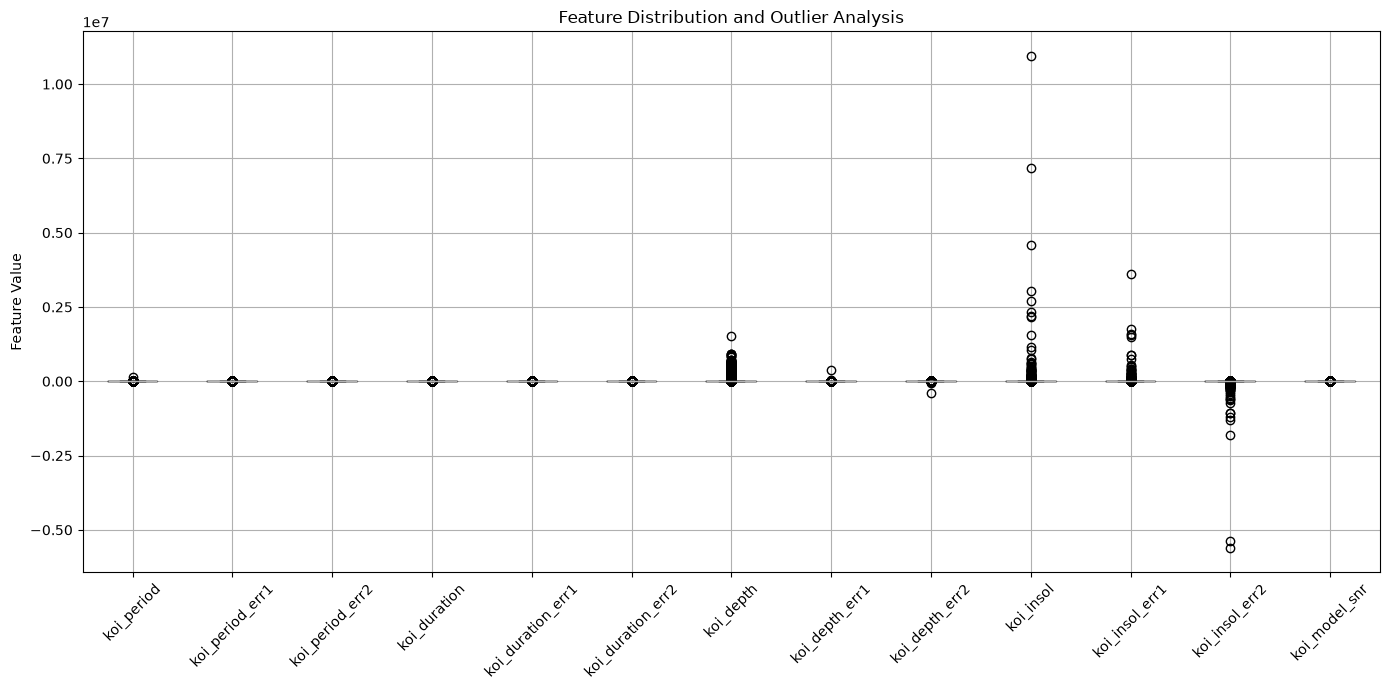

In [20]:
import matplotlib.pyplot as plt

features = df.drop(columns=["target"])

plt.figure(figsize=(14, 7))

features.boxplot()

plt.title("Feature Distribution and Outlier Analysis")
plt.ylabel("Feature Value")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [21]:
print(features.describe().T)

                    count          mean            std           min  \
koi_period         9564.0     75.671358    1334.744046  2.418425e-01   
koi_period_err1    9110.0      0.002148       0.008243  0.000000e+00   
koi_period_err2    9110.0     -0.002148       0.008243 -1.730000e-01   
koi_duration       9564.0      5.621606       6.471554  5.200000e-02   
koi_duration_err1  9110.0      0.339942       0.669823  0.000000e+00   
koi_duration_err2  9110.0     -0.339942       0.669823 -2.020000e+01   
koi_depth          9201.0  23792.453527   82243.161023  0.000000e+00   
koi_depth_err1     9110.0    123.233897    4116.741030  0.000000e+00   
koi_depth_err2     9110.0   -123.233897    4116.741030 -3.890000e+05   
koi_insol          9243.0   7745.737023  159204.665200  0.000000e+00   
koi_insol_err1     9243.0   3750.697910   55044.209142  0.000000e+00   
koi_insol_err2     9243.0  -4043.522368   88388.311174 -5.600031e+06   
koi_model_snr      9201.0    259.895001     795.806615  0.000000

In [22]:
print("\nFeature Skewness:")
print(features.skew().sort_values(ascending=False))


Feature Skewness:
koi_period           96.459326
koi_depth_err1       92.700565
koi_insol            49.947777
koi_insol_err1       42.902621
koi_period_err1       8.533040
koi_duration_err1     8.295464
koi_duration          5.928765
koi_model_snr         5.307083
koi_depth             5.259032
koi_duration_err2    -8.295464
koi_period_err2      -8.533040
koi_insol_err2      -53.738018
koi_depth_err2      -92.700565
dtype: float64


# train test split 

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Original:", X.shape)
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Original: (9564, 13)
Training: (7651, 13)
Testing : (1913, 13)


In [24]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training target distribution:
target
0    0.506731
1    0.493269
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.507057
1    0.492943
Name: proportion, dtype: float64


# <mark>preprocessing pipeline</mark> 

In [25]:
# ==========================================
# 1. DUPLICATE ROW CHECK
# ==========================================

duplicate_count = df.duplicated().sum()

print("Total rows      :", len(df))
print("Duplicate rows   :", duplicate_count)
print("Unique rows      :", len(df) - duplicate_count)

Total rows      : 9564
Duplicate rows   : 0
Unique rows      : 9564


# <mark> class balance check</mark>

In [26]:
# ==========================================
# 2. CLASS BALANCE CHECK
# ==========================================

class_counts = df["target"].value_counts()
class_percent = df["target"].value_counts(normalize=True) * 100

print("Class distribution:\n")

for cls in class_counts.index:
    print(
        f"Class {cls}: "
        f"{class_counts[cls]} samples "
        f"({class_percent[cls]:.2f}%)"
    )


Class distribution:

Class 0: 4847 samples (50.68%)
Class 1: 4717 samples (49.32%)


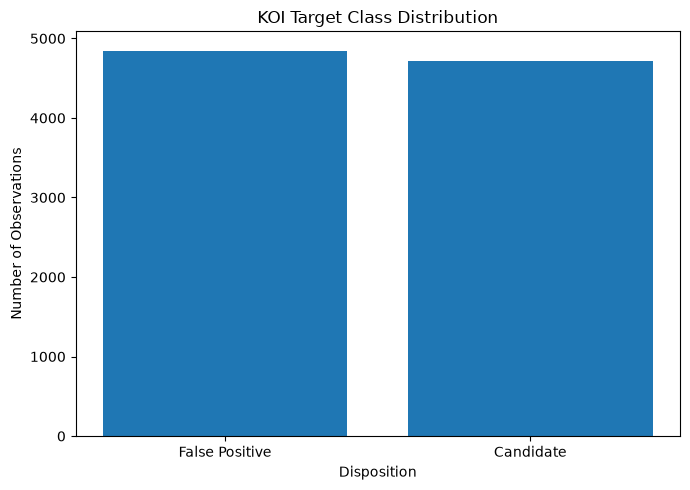

In [27]:
import matplotlib.pyplot as plt

labels = ["False Positive", "Candidate"]

plt.figure(figsize=(7, 5))

plt.bar(labels, [
    class_counts.get(0, 0),
    class_counts.get(1, 0)
])

plt.title("KOI Target Class Distribution")
plt.xlabel("Disposition")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [28]:
print("Data types:\n")
print(df.dtypes)

print("\nNon-numeric columns:")
print(df.select_dtypes(exclude="number").columns.tolist())

Data types:

koi_period           float64
koi_period_err1      float64
koi_period_err2      float64
koi_duration         float64
koi_duration_err1    float64
koi_duration_err2    float64
koi_depth            float64
koi_depth_err1       float64
koi_depth_err2       float64
koi_insol            float64
koi_insol_err1       float64
koi_insol_err2       float64
koi_model_snr        float64
target                 int64
dtype: object

Non-numeric columns:
[]


In [29]:
X = df.drop(columns=["target"])

for col in X.columns:
    unique_values = X[col].nunique(dropna=True)
    dominant_pct = X[col].value_counts(normalize=True, dropna=True).iloc[0] * 100

    print(
        f"{col:25} | "
        f"Unique: {unique_values:5} | "
        f"Most common value: {dominant_pct:.2f}%"
    )

koi_period                | Unique:  9564 | Most common value: 0.01%
koi_period_err1           | Unique:  3506 | Most common value: 0.20%
koi_period_err2           | Unique:  3506 | Most common value: 0.20%
koi_duration              | Unique:  7834 | Most common value: 0.06%
koi_duration_err1         | Unique:  2264 | Most common value: 0.76%
koi_duration_err2         | Unique:  2264 | Most common value: 0.76%
koi_depth                 | Unique:  2853 | Most common value: 0.27%
koi_depth_err1            | Unique:  1415 | Most common value: 0.45%
koi_depth_err2            | Unique:  1415 | Most common value: 0.45%
koi_insol                 | Unique:  7801 | Most common value: 0.12%
koi_insol_err1            | Unique:  7130 | Most common value: 1.29%
koi_insol_err2            | Unique:  6560 | Most common value: 1.28%
koi_model_snr             | Unique:  2740 | Most common value: 0.53%


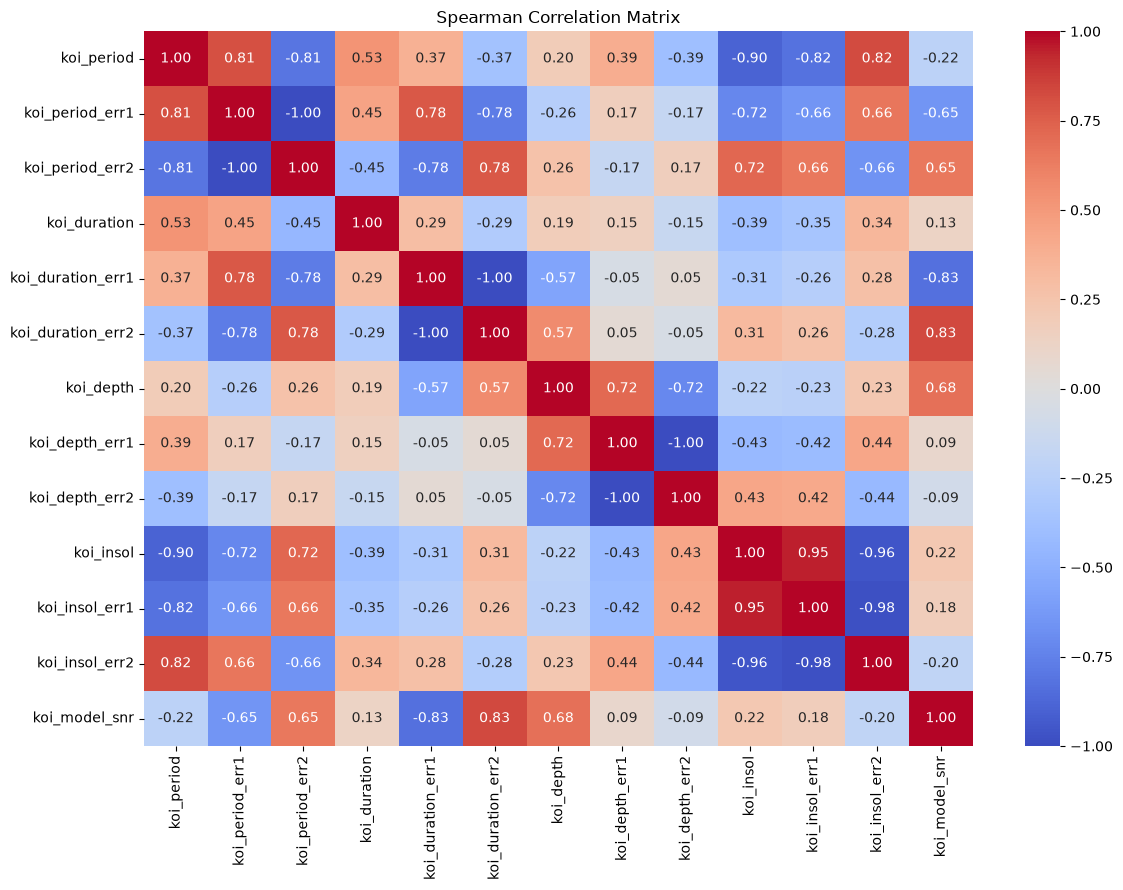

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

X = df.drop(columns=["target"])

corr_matrix = X.corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer
import pandas as pd

# Impute missing values using median
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Calculate VIF
vif = pd.DataFrame()
vif["Feature"] = X_train_imputed.columns
vif["VIF"] = [
    variance_inflation_factor(X_train_imputed.values, i)
    for i in range(X_train_imputed.shape[1])
]

vif = vif.sort_values("VIF", ascending=False)

print(vif.to_string(index=False))

C:\Users\Anmol\AppData\Local\Temp\ipykernel_20360\137402307.py:17: UserWarning: The design matrix is poorly conditioned (condition number=1.45e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_train_imputed.values, i)
C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\

          Feature          VIF
  koi_period_err1 1.000800e+15
koi_duration_err1 1.000800e+15
  koi_period_err2 1.000800e+15
   koi_depth_err1 1.000800e+15
koi_duration_err2 1.000800e+15
   koi_depth_err2 1.000800e+15
        koi_insol 2.570501e+01
   koi_insol_err2 1.606697e+01
   koi_insol_err1 8.537762e+00
        koi_depth 1.715845e+00
    koi_model_snr 1.606349e+00
       koi_period 1.554522e+00
     koi_duration 1.258834e+00


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [32]:
# Remove highly collinear insolation uncertainty features
X_train_vif = X_train.drop(
    columns=[
        "koi_period_err2",
        "koi_duration_err2",
        "koi_depth_err2",
        "koi_insol_err1",
        "koi_insol_err2"
    ]
)

# Impute missing values
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_vif),
    columns=X_train_vif.columns,
    index=X_train_vif.index
)

# Calculate VIF again
vif = pd.DataFrame()
vif["Feature"] = X_train_imputed.columns
vif["VIF"] = [
    variance_inflation_factor(X_train_imputed.values, i)
    for i in range(X_train_imputed.shape[1])
]

vif = vif.sort_values("VIF", ascending=False)

print(vif.to_string(index=False))

          Feature      VIF
  koi_period_err1 1.811740
        koi_depth 1.715707
    koi_model_snr 1.606314
koi_duration_err1 1.570634
       koi_period 1.553666
     koi_duration 1.258675
   koi_depth_err1 1.106982
        koi_insol 1.000696


In [33]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
import pandas as pd

# Final feature set after VIF analysis
selected_features = [
    "koi_period",
    "koi_period_err1",
    "koi_duration",
    "koi_duration_err1",
    "koi_depth",
    "koi_depth_err1",
    "koi_insol",
    "koi_model_snr"
]

X_mi = X_train[selected_features]
y_mi = y_train

# Impute missing values using training data
imputer_mi = SimpleImputer(strategy="median")
X_mi_imputed = imputer_mi.fit_transform(X_mi)

# Calculate Mutual Information
mi_scores = mutual_info_classif(
    X_mi_imputed,
    y_mi,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": selected_features,
    "MI Score": mi_scores
}).sort_values("MI Score", ascending=False)

print(mi_results.to_string(index=False))

          Feature  MI Score
       koi_period  0.116698
        koi_depth  0.102922
        koi_insol  0.091386
koi_duration_err1  0.088250
  koi_period_err1  0.083391
    koi_model_snr  0.072352
   koi_depth_err1  0.056156
     koi_duration  0.010326


In [36]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler

preprocessor_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power_transform", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Fit ONLY on training data
preprocessor_final.fit(X_train_final)

# Transform train and test
X_train_processed = preprocessor_final.transform(X_train_final)
X_test_processed = preprocessor_final.transform(X_test_final)

print("Before preprocessing:")
print("X_train:", X_train_final.shape)
print("X_test :", X_test_final.shape)

print("\nAfter preprocessing:")
print("X_train:", X_train_processed.shape)
print("X_test :", X_test_processed.shape)

Before preprocessing:
X_train: (7651, 8)
X_test : (1913, 8)

After preprocessing:
X_train: (7651, 8)
X_test : (1913, 8)


In [35]:
final_features = [
    "koi_period",
    "koi_period_err1",
    "koi_duration",
    "koi_duration_err1",
    "koi_depth",
    "koi_depth_err1",
    "koi_insol",
    "koi_model_snr"
]

X_train_final = X_train[final_features]
X_test_final = X_test[final_features]

print("Final training shape:", X_train_final.shape)
print("Final testing shape :", X_test_final.shape)

Final training shape: (7651, 8)
Final testing shape : (1913, 8)


# <mark> logistic regression </mark>

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create baseline model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train
logistic_model.fit(X_train_processed, y_train)

# Predictions
y_pred = logistic_model.predict(X_test_processed)
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Evaluation
print("Logistic Regression Results")
print("-" * 30)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Results
------------------------------
Accuracy : 0.7632
Precision: 0.7383
Recall   : 0.8049
F1 Score : 0.7702
ROC-AUC  : 0.8318

Confusion Matrix:
[[701 269]
 [184 759]]


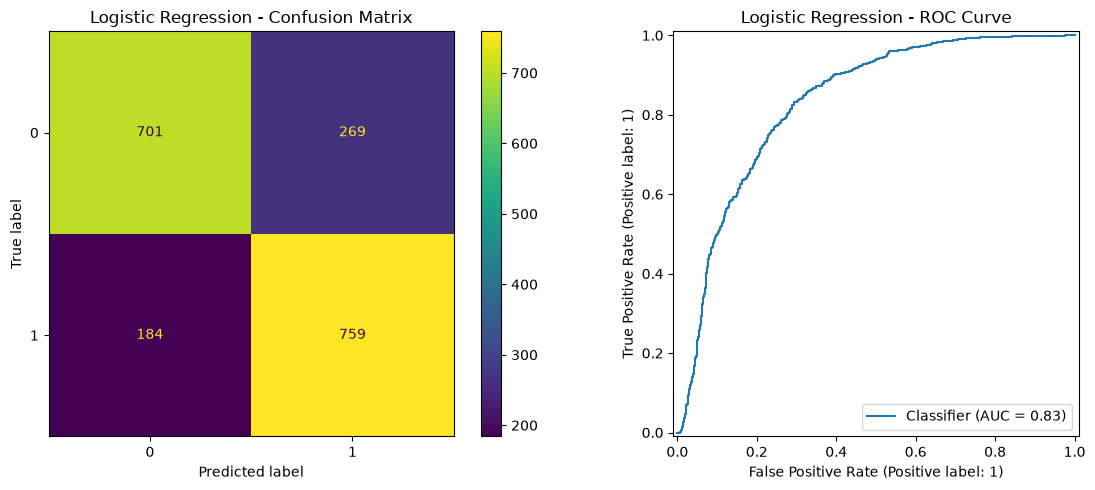

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression - Confusion Matrix")

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[1]
)
axes[1].set_title("Logistic Regression - ROC Curve")

plt.tight_layout()
plt.show()

#  <mark>random forest</mark>

In [39]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train_processed, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluation
print("Random Forest Results")
print("-" * 30)

print(f"Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
------------------------------
Accuracy : 0.8249
Precision: 0.8083
Recall   : 0.8452
F1 Score : 0.8263
ROC-AUC  : 0.9104

Confusion Matrix:
[[781 189]
 [146 797]]


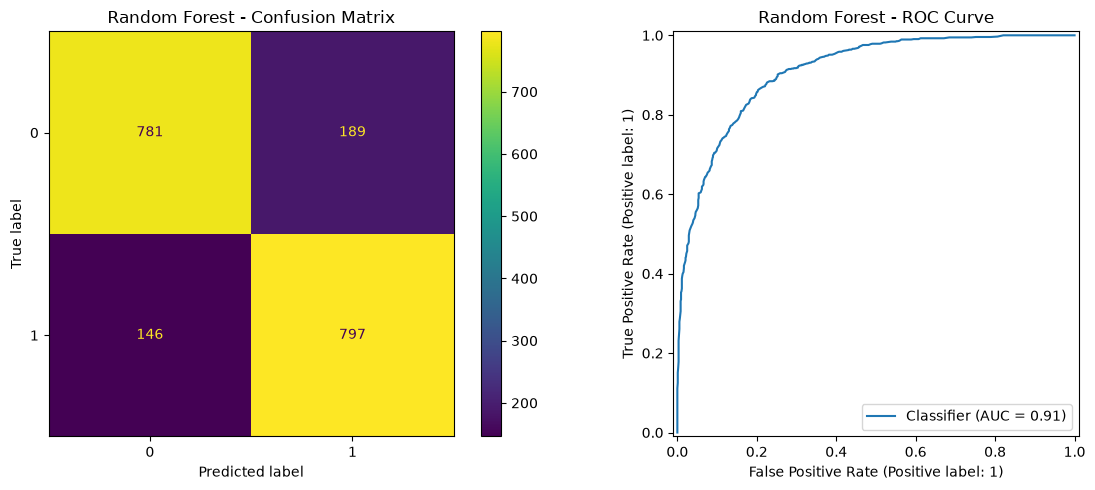

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    ax=axes[0]
)
axes[0].set_title("Random Forest - Confusion Matrix")

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    ax=axes[1]
)
axes[1].set_title("Random Forest - ROC Curve")

plt.tight_layout()
plt.show()

In [41]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    rf_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("5-Fold Cross-Validation Results")
print("-" * 35)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.upper():10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

5-Fold Cross-Validation Results
-----------------------------------
ACCURACY  : 0.8083 ± 0.0044
PRECISION : 0.8033 ± 0.0109
RECALL    : 0.8100 ± 0.0126
F1        : 0.8065 ± 0.0041
ROC_AUC   : 0.8985 ± 0.0043


In [42]:
from sklearn.ensemble import RandomForestClassifier

rf_model_final = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model_final.fit(X_train_processed, y_train)

y_pred_rf = rf_model_final.predict(X_test_processed)
y_prob_rf = rf_model_final.predict_proba(X_test_processed)[:, 1]

print("Random Forest trained on final 8 features.")
print("Training shape:", X_train_processed.shape)
print("Testing shape :", X_test_processed.shape)

Random Forest trained on final 8 features.
Training shape: (7651, 8)
Testing shape : (1913, 8)


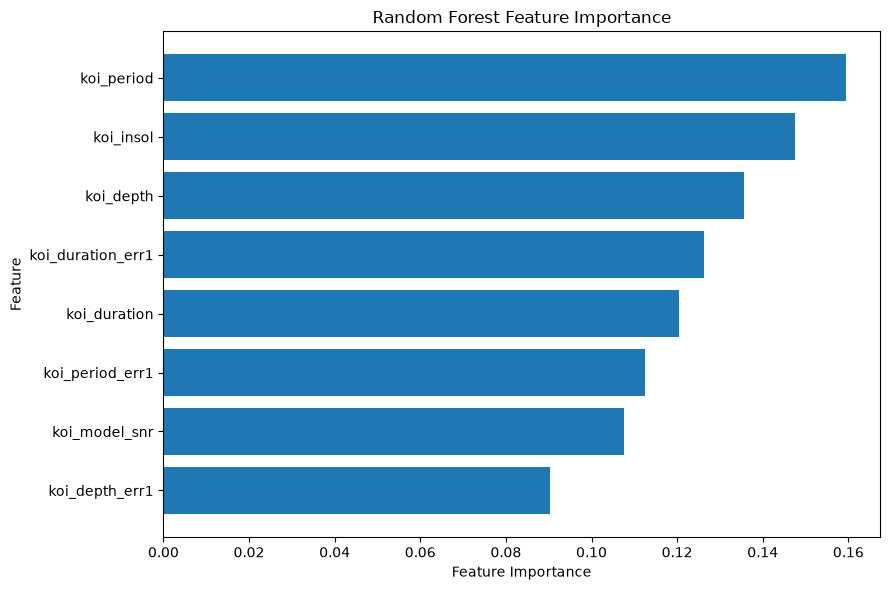

          Feature  Importance
       koi_period    0.159421
        koi_insol    0.147539
        koi_depth    0.135617
koi_duration_err1    0.126381
     koi_duration    0.120501
  koi_period_err1    0.112525
    koi_model_snr    0.107691
   koi_depth_err1    0.090324


In [43]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": final_features,
    "Importance": rf_model_final.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

print(
    feature_importance
    .sort_values("Importance", ascending=False)
    .to_string(index=False)
)

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    rf_model_final,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

print("Random Forest — 5-Fold Cross-Validation")
print("-" * 45)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Random Forest — 5-Fold Cross-Validation
---------------------------------------------
ACCURACY  : 0.8083 ± 0.0044
PRECISION : 0.8033 ± 0.0109
RECALL    : 0.8100 ± 0.0126
F1        : 0.8065 ± 0.0041
ROC_AUC   : 0.8985 ± 0.0043


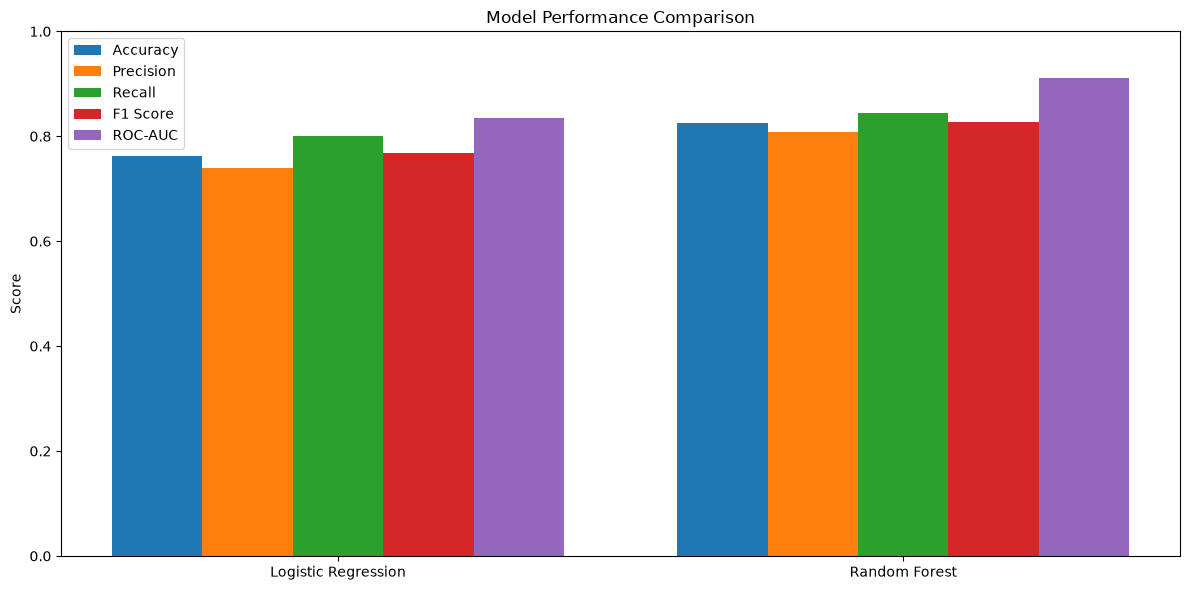

In [45]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "Random Forest"]

accuracy = [0.7622, 0.8249]
precision = [0.7387, 0.8083]
recall = [0.8006, 0.8452]
f1 = [0.7684, 0.8263]
roc_auc = [0.8352, 0.9104]

x = np.arange(len(models))
width = 0.16

plt.figure(figsize=(12, 6))

plt.bar(x - 2*width, accuracy, width, label="Accuracy")
plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1, width, label="F1 Score")
plt.bar(x + 2*width, roc_auc, width, label="ROC-AUC")

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

In [46]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(f"{grid_search.best_score_:.4f}")

KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Best model found by GridSearchCV
best_rf = grid_search.best_estimator_

# Test-set predictions
y_pred_tuned = best_rf.predict(X_test_processed)
y_prob_tuned = best_rf.predict_proba(X_test_processed)[:, 1]

print("Tuned Random Forest Results")
print("-" * 35)

print(f"Accuracy : {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_tuned):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_tuned):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

hgb_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    random_state=42
)

hgb_model.fit(X_train_processed, y_train)

y_pred_hgb = hgb_model.predict(X_test_processed)
y_prob_hgb = hgb_model.predict_proba(X_test_processed)[:, 1]

print("HistGradientBoosting Results")
print("-" * 35)
print("Accuracy :", accuracy_score(y_test, y_pred_hgb))
print("Precision:", precision_score(y_test, y_pred_hgb))
print("Recall   :", recall_score(y_test, y_pred_hgb))
print("F1 Score :", f1_score(y_test, y_pred_hgb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_hgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_hgb))

In [ ]:
from sklearn.model_selection import GridSearchCV

hgb_param_grid = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 300, 500],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 30],
    "l2_regularization": [0, 0.1, 1.0]
}

hgb_grid = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=42
    ),
    param_grid=hgb_param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

hgb_grid.fit(X_train_processed, y_train)

print("Best Parameters:")
print(hgb_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(hgb_grid.best_score_)

In [ ]:
!pip install xgboost 
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

print("XGBoost Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall   :", recall_score(y_test, y_pred_xgb))
print("F1 Score :", f1_score(y_test, y_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

xgb_param_dist = {
    "n_estimators": randint(200, 700),
    "max_depth": randint(3, 10),
    "learning_rate": uniform(0.02, 0.10),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "min_child_weight": randint(1, 10),
    "gamma": uniform(0, 0.5),
    "reg_alpha": uniform(0, 0.5),
    "reg_lambda": uniform(0.5, 2.0)
}

xgb_random = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),
    param_distributions=xgb_param_dist,
    n_iter=50,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random.fit(X_train_processed, y_train)

print("Best Parameters:")
print(xgb_random.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_random.best_score_)

In [ ]:
best_xgb = xgb_random.best_estimator_

best_xgb.fit(X_train_processed, y_train)

y_pred_xgb_tuned = best_xgb.predict(X_test_processed)
y_prob_xgb_tuned = best_xgb.predict_proba(X_test_processed)[:, 1]

print("Tuned XGBoost Results")
print("-" * 35)
print("Accuracy :", accuracy_score(y_test, y_pred_xgb_tuned))
print("Precision:", precision_score(y_test, y_pred_xgb_tuned))
print("Recall   :", recall_score(y_test, y_pred_xgb_tuned))
print("F1 Score :", f1_score(y_test, y_pred_xgb_tuned))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_tuned))

In [ ]:
!pip install lightgbm
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

In [ ]:
!python.exe -m pip install --upgrade pip

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train_processed, y_train)

y_pred_lgb = lgb_model.predict(X_test_processed)
y_prob_lgb = lgb_model.predict_proba(X_test_processed)[:, 1]

print("LightGBM Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_lgb))
print("Precision:", precision_score(y_test, y_pred_lgb))
print("Recall   :", recall_score(y_test, y_pred_lgb))
print("F1 Score :", f1_score(y_test, y_pred_lgb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgb))

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

y_pred_svm = svm_model.predict(X_test_processed)
y_prob_svm = svm_model.predict_proba(X_test_processed)[:, 1]

print("SVM (RBF) Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall   :", recall_score(y_test, y_pred_svm))
print("F1 Score :", f1_score(y_test, y_pred_svm))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

extra_model = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

extra_model.fit(X_train_processed, y_train)

y_pred_extra = extra_model.predict(X_test_processed)
y_prob_extra = extra_model.predict_proba(X_test_processed)[:, 1]

print("Extra Trees Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_extra))
print("Precision:", precision_score(y_test, y_pred_extra))
print("Recall   :", recall_score(y_test, y_pred_extra))
print("F1 Score :", f1_score(y_test, y_pred_extra))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_extra))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_extra))

In [ ]:
!pip install catboost

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False
)

cat_model.fit(X_train_processed, y_train)

y_pred_cat = cat_model.predict(X_test_processed).ravel()
y_prob_cat = cat_model.predict_proba(X_test_processed)[:, 1]

print("CatBoost Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_cat))
print("Precision:", precision_score(y_test, y_pred_cat))
print("Recall   :", recall_score(y_test, y_pred_cat))
print("F1 Score :", f1_score(y_test, y_pred_cat))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_cat))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cat))


In [48]:
import torch
print("PyTorch:", torch.__version__)

from pytorch_tabnet.tab_model import TabNetClassifier
print("TabNet is available!")

PyTorch: 2.11.0+cu128
TabNet is available!


In [54]:
import torch
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_model = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_model.fit(
    X_train_processed.astype("float32"),
    y_train.values,
    eval_set=[
        (
            X_test_processed.astype("float32"),
            y_test.values
        )
    ],
    eval_name=["test"],
    eval_metric=["auc"],
    max_epochs=100,
    patience=15,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.56137 | test_auc: 0.84724 |  0:00:03s
epoch 10 | loss: 0.40105 | test_auc: 0.90957 |  0:00:33s
epoch 20 | loss: 0.38211 | test_auc: 0.9134  |  0:01:06s
epoch 30 | loss: 0.36551 | test_auc: 0.92351 |  0:01:39s
epoch 40 | loss: 0.3582  | test_auc: 0.92101 |  0:02:12s
epoch 50 | loss: 0.34316 | test_auc: 0.91961 |  0:02:46s
epoch 60 | loss: 0.33378 | test_auc: 0.92671 |  0:03:19s

Early stopping occurred at epoch 60 with best_epoch = 45 and best_test_auc = 0.92769


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [ ]:
print("hello")

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_pred_tabnet = tabnet_model.predict(
    X_test_processed.astype("float32")
).ravel()

y_prob_tabnet = tabnet_model.predict_proba(
    X_test_processed.astype("float32")
)[:, 1]

print("TabNet Results")
print("-" * 30)
print("Accuracy :", accuracy_score(y_test, y_pred_tabnet))
print("Precision:", precision_score(y_test, y_pred_tabnet))
print("Recall   :", recall_score(y_test, y_pred_tabnet))
print("F1 Score :", f1_score(y_test, y_pred_tabnet))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tabnet))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tabnet))

# tabnet split 

In [59]:
from sklearn.model_selection import train_test_split

X_tab_train, X_tab_val, y_tab_train, y_tab_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("TabNet training:", X_tab_train.shape)
print("TabNet validation:", X_tab_val.shape)
print("Final test:", X_test_processed.shape)

TabNet training: (6120, 8)
TabNet validation: (1531, 8)
Final test: (1913, 8)


In [60]:
import torch
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_clean = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_clean.fit(
    X_tab_train.astype("float32"),
    y_tab_train.values,
    eval_set=[
        (
            X_tab_val.astype("float32"),
            y_tab_val.values
        )
    ],
    eval_name=["validation"],
    eval_metric=["auc"],
    max_epochs=100,
    patience=15,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.59232 | validation_auc: 0.81292 |  0:00:02s
epoch 10 | loss: 0.3947  | validation_auc: 0.88615 |  0:00:27s
epoch 20 | loss: 0.3789  | validation_auc: 0.89483 |  0:00:55s
epoch 30 | loss: 0.36415 | validation_auc: 0.89777 |  0:01:21s
epoch 40 | loss: 0.36089 | validation_auc: 0.89713 |  0:01:44s
epoch 50 | loss: 0.34284 | validation_auc: 0.89821 |  0:02:07s

Early stopping occurred at epoch 52 with best_epoch = 37 and best_validation_auc = 0.9054


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_pred_tabnet_clean = tabnet_clean.predict(
    X_test_processed.astype("float32")
).ravel()

y_prob_tabnet_clean = tabnet_clean.predict_proba(
    X_test_processed.astype("float32")
)[:, 1]

print("Clean TabNet Results")
print("-" * 35)
print("Accuracy :", accuracy_score(y_test, y_pred_tabnet_clean))
print("Precision:", precision_score(y_test, y_pred_tabnet_clean))
print("Recall   :", recall_score(y_test, y_pred_tabnet_clean))
print("F1 Score :", f1_score(y_test, y_pred_tabnet_clean))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tabnet_clean))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tabnet_clean))

Clean TabNet Results
-----------------------------------
Accuracy : 0.8259278619968635
Precision: 0.8359030837004405
Recall   : 0.8048780487804879
F1 Score : 0.820097244732577
ROC-AUC  : 0.9228859419925441

Confusion Matrix:
[[821 149]
 [184 759]]


In [62]:
# All legitimate features before VIF-based feature removal
original_13_features = [
    "koi_period",
    "koi_period_err1",
    "koi_period_err2",
    "koi_duration",
    "koi_duration_err1",
    "koi_duration_err2",
    "koi_depth",
    "koi_depth_err1",
    "koi_depth_err2",
    "koi_insol",
    "koi_insol_err1",
    "koi_insol_err2",
    "koi_model_snr"
]

# Select the 13 features
X_train_13 = X_train[original_13_features]
X_test_13 = X_test[original_13_features]

# Preprocessing pipeline
preprocessor_13 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power_transform", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Fit ONLY on training data
preprocessor_13.fit(X_train_13)

# Transform train and test
X_train_13_processed = preprocessor_13.transform(X_train_13)
X_test_13_processed = preprocessor_13.transform(X_test_13)

print("Training shape:", X_train_13_processed.shape)
print("Test shape:", X_test_13_processed.shape)

Training shape: (7651, 13)
Test shape: (1913, 13)


In [63]:
from sklearn.model_selection import train_test_split

X_tabnet_train, X_tabnet_val, y_tabnet_train, y_tabnet_val = train_test_split(
    X_train_13_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("TabNet training shape:", X_tabnet_train.shape)
print("TabNet validation shape:", X_tabnet_val.shape)
print("Final test shape:", X_test_13_processed.shape)

print("\nTarget distribution:")
print("Train:", y_tabnet_train.value_counts().to_dict())
print("Validation:", y_tabnet_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

TabNet training shape: (6120, 13)
TabNet validation shape: (1531, 13)
Final test shape: (1913, 13)

Target distribution:
Train: {0: 3101, 1: 3019}
Validation: {0: 776, 1: 755}
Test: {0: 970, 1: 943}


In [64]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_13 = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cpu"
)

tabnet_13.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=100,
    patience=15,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.58672 | train_auc: 0.78702 | validation_auc: 0.7736  |  0:00:02s
epoch 10 | loss: 0.38989 | train_auc: 0.9135  | validation_auc: 0.8888  |  0:00:33s
epoch 20 | loss: 0.37419 | train_auc: 0.90298 | validation_auc: 0.87552 |  0:01:02s
epoch 30 | loss: 0.36645 | train_auc: 0.9237  | validation_auc: 0.89903 |  0:01:32s
epoch 40 | loss: 0.35151 | train_auc: 0.92308 | validation_auc: 0.89353 |  0:02:01s
epoch 50 | loss: 0.34638 | train_auc: 0.92724 | validation_auc: 0.90021 |  0:02:31s

Early stopping occurred at epoch 50 with best_epoch = 35 and best_validation_auc = 0.90688


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predictions on the untouched test set
y_pred_13 = tabnet_13.predict(X_test_13_processed)
y_prob_13 = tabnet_13.predict_proba(X_test_13_processed)[:, 1]

# Metrics
accuracy_13 = accuracy_score(y_test, y_pred_13)
precision_13 = precision_score(y_test, y_pred_13)
recall_13 = recall_score(y_test, y_pred_13)
f1_13 = f1_score(y_test, y_pred_13)
roc_auc_13 = roc_auc_score(y_test, y_prob_13)
cm_13 = confusion_matrix(y_test, y_pred_13)

print(f"Accuracy : {accuracy_13:.4f}")
print(f"Precision: {precision_13:.4f}")
print(f"Recall   : {recall_13:.4f}")
print(f"F1 Score : {f1_13:.4f}")
print(f"ROC-AUC  : {roc_auc_13:.4f}")

print("\nConfusion Matrix:")
print(cm_13)

Accuracy : 0.8400
Precision: 0.8496
Recall   : 0.8208
F1 Score : 0.8350
ROC-AUC  : 0.9253

Confusion Matrix:
[[833 137]
 [169 774]]


In [66]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_13_long = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_13_long.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=300,
    patience=30,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.58672 | train_auc: 0.78702 | validation_auc: 0.7736  |  0:00:02s
epoch 10 | loss: 0.38989 | train_auc: 0.9135  | validation_auc: 0.8888  |  0:00:32s
epoch 20 | loss: 0.37419 | train_auc: 0.90298 | validation_auc: 0.87552 |  0:01:02s
epoch 30 | loss: 0.36645 | train_auc: 0.9237  | validation_auc: 0.89903 |  0:01:31s
epoch 40 | loss: 0.35151 | train_auc: 0.92308 | validation_auc: 0.89353 |  0:02:00s
epoch 50 | loss: 0.34638 | train_auc: 0.92724 | validation_auc: 0.90021 |  0:02:30s
epoch 60 | loss: 0.34735 | train_auc: 0.93488 | validation_auc: 0.90116 |  0:02:59s
epoch 70 | loss: 0.32807 | train_auc: 0.94278 | validation_auc: 0.90238 |  0:03:29s
epoch 80 | loss: 0.36428 | train_auc: 0.92634 | validation_auc: 0.89648 |  0:03:58s
epoch 90 | loss: 0.32363 | train_auc: 0.93873 | validation_auc: 0.89926 |  0:04:28s

Early stopping occurred at epoch 93 with best_epoch = 63 and best_validation_auc = 0.90832


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [68]:
import sys 
print(sys.executable)

C:\Users\Anmol\projectLoka\.venv\Scripts\python.exe


In [69]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_13_200 = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_13_200.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=200,
    patience=200,          # effectively no early stopping
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.58355 | train_auc: 0.78449 | validation_auc: 0.77441 |  0:00:03s
epoch 10 | loss: 0.3971  | train_auc: 0.91108 | validation_auc: 0.8839  |  0:00:44s
epoch 20 | loss: 0.3716  | train_auc: 0.92417 | validation_auc: 0.89227 |  0:01:20s
epoch 30 | loss: 0.3676  | train_auc: 0.92683 | validation_auc: 0.89176 |  0:01:56s
epoch 40 | loss: 0.35448 | train_auc: 0.93253 | validation_auc: 0.89769 |  0:02:31s
epoch 50 | loss: 0.33714 | train_auc: 0.94092 | validation_auc: 0.90512 |  0:03:07s
epoch 60 | loss: 0.34208 | train_auc: 0.94126 | validation_auc: 0.90095 |  0:03:43s
epoch 70 | loss: 0.33438 | train_auc: 0.92105 | validation_auc: 0.8851  |  0:04:19s
epoch 80 | loss: 0.34041 | train_auc: 0.93675 | validation_auc: 0.9026  |  0:04:55s
epoch 90 | loss: 0.32643 | train_auc: 0.93551 | validation_auc: 0.89936 |  0:05:30s
epoch 100| loss: 0.31257 | train_auc: 0.93894 | validation_auc: 0.89852 |  0:06:06s
epoch 110| loss: 0.31222 | train_auc: 0.94846 | validation_auc: 0.89947 |  0

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Evaluate the final model after 200 epochs
y_pred_200 = tabnet_13_200.predict(X_test_13_processed)
y_prob_200 = tabnet_13_200.predict_proba(X_test_13_processed)[:, 1]

accuracy_200 = accuracy_score(y_test, y_pred_200)
precision_200 = precision_score(y_test, y_pred_200)
recall_200 = recall_score(y_test, y_pred_200)
f1_200 = f1_score(y_test, y_pred_200)
roc_auc_200 = roc_auc_score(y_test, y_prob_200)
cm_200 = confusion_matrix(y_test, y_pred_200)

print(f"Accuracy : {accuracy_200:.4f}")
print(f"Precision: {precision_200:.4f}")
print(f"Recall   : {recall_200:.4f}")
print(f"F1 Score : {f1_200:.4f}")
print(f"ROC-AUC  : {roc_auc_200:.4f}")

print("\nConfusion Matrix:")
print(cm_200)

Accuracy : 0.8380
Precision: 0.8200
Recall   : 0.8600
F1 Score : 0.8395
ROC-AUC  : 0.9275

Confusion Matrix:
[[792 178]
 [132 811]]


In [71]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_tuned_1 = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=5,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_tuned_1.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.68298 | train_auc: 0.80979 | validation_auc: 0.79542 |  0:00:04s
epoch 10 | loss: 0.39721 | train_auc: 0.90395 | validation_auc: 0.88288 |  0:01:05s
epoch 20 | loss: 0.37599 | train_auc: 0.91399 | validation_auc: 0.89076 |  0:02:01s
epoch 30 | loss: 0.36818 | train_auc: 0.92228 | validation_auc: 0.89775 |  0:02:43s
epoch 40 | loss: 0.36426 | train_auc: 0.91362 | validation_auc: 0.89214 |  0:03:27s
epoch 50 | loss: 0.35252 | train_auc: 0.92811 | validation_auc: 0.9001  |  0:04:09s
epoch 60 | loss: 0.35295 | train_auc: 0.929   | validation_auc: 0.90346 |  0:04:54s
epoch 70 | loss: 0.34047 | train_auc: 0.9355  | validation_auc: 0.90201 |  0:05:37s
epoch 80 | loss: 0.33615 | train_auc: 0.93523 | validation_auc: 0.90286 |  0:06:20s
epoch 90 | loss: 0.3416  | train_auc: 0.9302  | validation_auc: 0.89749 |  0:07:03s

Early stopping occurred at epoch 97 with best_epoch = 72 and best_validation_auc = 0.91057


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Test predictions
y_pred_tuned1 = tabnet_tuned_1.predict(X_test_13_processed)
y_prob_tuned1 = tabnet_tuned_1.predict_proba(X_test_13_processed)[:, 1]

# Metrics
accuracy_tuned1 = accuracy_score(y_test, y_pred_tuned1)
precision_tuned1 = precision_score(y_test, y_pred_tuned1)
recall_tuned1 = recall_score(y_test, y_pred_tuned1)
f1_tuned1 = f1_score(y_test, y_pred_tuned1)
roc_auc_tuned1 = roc_auc_score(y_test, y_prob_tuned1)
cm_tuned1 = confusion_matrix(y_test, y_pred_tuned1)

print(f"Accuracy : {accuracy_tuned1:.4f}")
print(f"Precision: {precision_tuned1:.4f}")
print(f"Recall   : {recall_tuned1:.4f}")
print(f"F1 Score : {f1_tuned1:.4f}")
print(f"ROC-AUC  : {roc_auc_tuned1:.4f}")

print("\nConfusion Matrix:")
print(cm_tuned1)

Accuracy : 0.8406
Precision: 0.8401
Recall   : 0.8356
F1 Score : 0.8379
ROC-AUC  : 0.9302

Confusion Matrix:
[[820 150]
 [155 788]]


higher gamma tab net


In [74]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_tuned_2 = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=5,
    gamma=1.5,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_tuned_2.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.70018 | train_auc: 0.78337 | validation_auc: 0.7507  |  0:00:05s
epoch 10 | loss: 0.43809 | train_auc: 0.8832  | validation_auc: 0.86631 |  0:00:48s
epoch 20 | loss: 0.39298 | train_auc: 0.91093 | validation_auc: 0.88331 |  0:01:30s
epoch 30 | loss: 0.38953 | train_auc: 0.91392 | validation_auc: 0.88552 |  0:02:13s
epoch 40 | loss: 0.3638  | train_auc: 0.92408 | validation_auc: 0.89609 |  0:02:54s
epoch 50 | loss: 0.3518  | train_auc: 0.928   | validation_auc: 0.90175 |  0:03:53s
epoch 60 | loss: 0.34259 | train_auc: 0.93309 | validation_auc: 0.90492 |  0:04:35s
epoch 70 | loss: 0.34441 | train_auc: 0.91792 | validation_auc: 0.8935  |  0:05:16s
epoch 80 | loss: 0.33735 | train_auc: 0.92946 | validation_auc: 0.89974 |  0:05:56s
epoch 90 | loss: 0.32441 | train_auc: 0.94005 | validation_auc: 0.90299 |  0:06:37s
epoch 100| loss: 0.33275 | train_auc: 0.94217 | validation_auc: 0.90806 |  0:07:17s
epoch 110| loss: 0.32388 | train_auc: 0.93588 | validation_auc: 0.89872 |  0

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [75]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_tuned_3 = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=5,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=1e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_tuned_3.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.68141 | train_auc: 0.81675 | validation_auc: 0.80369 |  0:00:04s
epoch 10 | loss: 0.40933 | train_auc: 0.89852 | validation_auc: 0.87435 |  0:00:47s
epoch 20 | loss: 0.38131 | train_auc: 0.91582 | validation_auc: 0.87999 |  0:01:30s
epoch 30 | loss: 0.3709  | train_auc: 0.92253 | validation_auc: 0.89414 |  0:02:11s
epoch 40 | loss: 0.36568 | train_auc: 0.92824 | validation_auc: 0.90218 |  0:02:52s
epoch 50 | loss: 0.34607 | train_auc: 0.93535 | validation_auc: 0.90304 |  0:03:33s
epoch 60 | loss: 0.34339 | train_auc: 0.93376 | validation_auc: 0.90112 |  0:04:16s
epoch 70 | loss: 0.33629 | train_auc: 0.93338 | validation_auc: 0.90383 |  0:05:00s
epoch 80 | loss: 0.31937 | train_auc: 0.9456  | validation_auc: 0.90332 |  0:05:45s
epoch 90 | loss: 0.31837 | train_auc: 0.94706 | validation_auc: 0.90433 |  0:06:41s
epoch 100| loss: 0.31715 | train_auc: 0.94245 | validation_auc: 0.90034 |  0:07:21s
epoch 110| loss: 0.30877 | train_auc: 0.95051 | validation_auc: 0.89968 |  0

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [76]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_tuned_4 = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=7,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=42,
    verbose=10,
    device_name="cuda"
)

tabnet_tuned_4.fit(
    X_tabnet_train,
    y_tabnet_train.values,
    eval_set=[
        (X_tabnet_train, y_tabnet_train.values),
        (X_tabnet_val, y_tabnet_val.values)
    ],
    eval_name=["train", "validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.70075 | train_auc: 0.82221 | validation_auc: 0.80576 |  0:00:05s
epoch 10 | loss: 0.46008 | train_auc: 0.87786 | validation_auc: 0.85997 |  0:01:01s
epoch 20 | loss: 0.41943 | train_auc: 0.89638 | validation_auc: 0.87821 |  0:01:57s
epoch 30 | loss: 0.41305 | train_auc: 0.90412 | validation_auc: 0.87807 |  0:02:54s
epoch 40 | loss: 0.40075 | train_auc: 0.90155 | validation_auc: 0.87165 |  0:03:50s
epoch 50 | loss: 0.39304 | train_auc: 0.89586 | validation_auc: 0.86549 |  0:04:44s
epoch 60 | loss: 0.38478 | train_auc: 0.9087  | validation_auc: 0.88602 |  0:05:41s
epoch 70 | loss: 0.38978 | train_auc: 0.91078 | validation_auc: 0.88729 |  0:06:36s
epoch 80 | loss: 0.36624 | train_auc: 0.92392 | validation_auc: 0.89403 |  0:07:31s
epoch 90 | loss: 0.36506 | train_auc: 0.9268  | validation_auc: 0.89391 |  0:08:26s
epoch 100| loss: 0.36057 | train_auc: 0.9211  | validation_auc: 0.89074 |  0:09:21s

Early stopping occurred at epoch 106 with best_epoch = 81 and best_validati

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [1]:
import torch

OSError: [WinError 126] The specified module could not be found. Error loading "C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\torch\lib\c10_cuda.dll" or one of its dependencies.

In [2]:
from pytorch_tabnet.tab_model import TabNetClassifier


OSError: [WinError 126] The specified module could not be found. Error loading "C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\torch\lib\caffe2_nvrtc.dll" or one of its dependencies.

In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA GeForce RTX 2050
